# Numeric Cu/Cu2O/CuO reference comparison
Original notebook is immutable at `raw/Cu_XAS.ipynb`; its complete cell audit is `original_notebook_cells.json`. Folder names are aliases: oxide FDMNES modes are classified from decks/logs. “GW” does not establish GW/BSE. Three missing calculation slots stay blank. Formal Cu(0/I/II) labels are not atomic charges.

Native/common/per-compound alignment and the unvalidated notebook Gaussian sensitivity are separate. Short pre-edge support limits normalization; comparisons do not establish absolute accuracy or a universal method ranking. See README.md, settings.json and provenance.csv for all prescriptions and limitations.

In [1]:
from pathlib import Path
import subprocess, sys, pandas as pd
root = Path.cwd()
if not (root / "process.py").exists():
    root = root / "study" / "reference_benchmark"
assert (root / "raw" / "Cu_XAS.ipynb").is_file()
result = subprocess.run([sys.executable, str(root / "process.py")], check=True, text=True, capture_output=True)
print(result.stdout)

method   experiment fdmnes_fdm fdmnes_green       feff    vasp_gw   vasp_pbe
material                                                                    
Cu        available  available    available  available  available  available
Cu2O      available  available    available  available    missing    missing
CuO       available  available    available  available  available    missing
material       method    nrmse  correlation  shift_eV
      Cu fdmnes_green 0.053888     0.986608 -0.185715
      Cu   fdmnes_fdm 0.089555     0.870343 -0.185715
      Cu         feff 0.100221     0.966766 -8.323343
      Cu     vasp_pbe 0.253930     0.163998 85.557805
      Cu      vasp_gw 0.371483    -0.765483 85.557805
    Cu2O fdmnes_green 0.103059     0.977924 -0.185715
    Cu2O   fdmnes_fdm 0.106928     0.977808 -0.185715
    Cu2O         feff 0.248884     0.840263 -8.323343
     CuO fdmnes_green 0.137799     0.964243 -0.185715
     CuO   fdmnes_fdm 0.954040     0.862463 -0.185715
     CuO         feff

In [2]:
import json
settings = json.loads((root / "settings.json").read_text())
print(json.dumps(settings, indent=2))
display(pd.read_csv(root / "provenance.csv"))

{
  "protocol": "reference-v1",
  "pre_window_eV": [
    8974.0,
    8976.0
  ],
  "post_window_eV": [
    9020.0,
    9028.0
  ],
  "metric_interpretation": "conditional short-window local edge-jump comparison, not standardized absolute accuracy; conventional long pre-edge regression is unsupported by FDMNES range",
  "metric_window_eV": [
    8980.0,
    9020.0
  ],
  "grid_step_eV": 0.2,
  "shift_sign": "E_plotted = E_input + shift_eV",
  "common_calibration": "one shift per backend fitted on Cu only; shared by all compounds and FDMNES modes",
  "common_shift_bounds_eV": {
    "fdmnes": [
      -20.0,
      20.0
    ],
    "feff": [
      -25.0,
      25.0
    ],
    "vasp": [
      0.0,
      200.0
    ]
  },
  "shape_residual_shift_bounds_eV": [
    -20.0,
    20.0
  ],
  "objective": "edge-jump normalized RMSE on 8980\u20139020 eV, 0.2 eV linear grid; no extrapolation",
  "fit_degrees_of_freedom": "common: 1 backend shift on Cu; optional shape: 1 residual shift per available comp

,material,formal_oxidation_state,method,status,source_file,sha256,numeric_columns_units,energy_convention,averaging,processing_present,settings,limitation,repository_sha256
0,Cu,0,fdmnes_green,available,raw/Cu/fdm_green/Cu_conv.txt,421d6166dd0a9e1fdd7b7cf0f8abafc9bfcfeef75dbe79...,"Energy/eV, <xanes>/Mbarn per represented absor...",Energpho photon-energy axis; native convolutio...,<xanes> isotropic; native represented absorber...,energy-dependent native convolution retained,Revision 11 April 2025; radius 7 Angstrom; SCF...,NaN,421d6166dd0a9e1fdd7b7cf0f8abafc9bfcfeef75dbe79...
1,Cu,0,fdmnes_fdm,available,raw/Cu/fdm_fdm/Cu_conv.txt,634f639482736a2fc5b42a8b3f6f52681bfe3747720fd8...,"Energy/eV, <xanes>/Mbarn per represented absor...",Energpho photon-energy axis; native convolutio...,<xanes> isotropic; native represented absorber...,energy-dependent native convolution retained,Revision 11 April 2025; radius 7 Angstrom; SCF...,NaN,634f639482736a2fc5b42a8b3f6f52681bfe3747720fd8...
2,Cu,0,feff,available,raw/Cu/feff/xmu.dat,7440caa9ed6e44a6f5d6abb6507af5949308fbbe83f7be...,"column 0 omega/eV, column 3 mu/FEFF edge-norma...",omega photon energy (not relative e column),"single symmetry-representative Cu absorber, un...",intrinsic lifetime and Hedin-Lundqvist self en...,FEFF 9.6.4; COREHOLE RPA; SCF 7 Angstrom; FMS ...,NaN,7440caa9ed6e44a6f5d6abb6507af5949308fbbe83f7be...
3,Cu,0,vasp_pbe,available,raw/Cu/PBE/XAS/OUTCAR.gz,e640834cd4e0259bed3857a7d73daf1197c47c0fe2e797...,"E/eV; arithmetic mean of X,Y,Z imaginary diele...",native VASP core-excitation energy; lacks abso...,"trace/3 dielectric tensor, single designated c...",CH_SIGMA=0.1 eV built-in broadening; not a sti...,vasp.6.3.2 27Jun22 (build May 28 2024 15:01:12...,"folder GW is an alias, no GW/BSE step verified...",c7e9417be1b0b88d0156650742955eade453b7663e1ea4...
4,Cu,0,vasp_gw,available,raw/Cu/GW/XAS/OUTCAR.gz,b5344c2cf05e4e7a9cfe9ab345f718b9ccb70af076c2ad...,"E/eV; arithmetic mean of X,Y,Z imaginary diele...",native VASP core-excitation energy; lacks abso...,"trace/3 dielectric tensor, single designated c...",CH_SIGMA=0.1 eV built-in broadening; not a sti...,vasp.6.3.2 27Jun22 (build May 28 2024 15:01:12...,"folder GW is an alias, no GW/BSE step verified...",44d9042b634b27f4e7ebe575a960fa2c44ebc34c45f616...
5,Cu,0,experiment,available,raw/260324_export_XAS_Exp_ref_stds.dat,e71283b014db4d214bb8970b2c2285ee33f5d37cfff6ff...,column 0 Energy/eV; column 1 merge_14-15-16_E2...,"supplied photon energy, unchanged",merged traces per header; polarization not rep...,merged and apparently normalized export; upstr...,NaN,"Cu header identifies 100 nm Cu at -0.4 V, not ...",e71283b014db4d214bb8970b2c2285ee33f5d37cfff6ff...
6,Cu2O,1,fdmnes_green,available,raw/Cu2O/fdm_fdm/Cu2O_fdm_conv.txt,b5de74f09488bed58c5f81a41fda97596c20ce24a6c2d2...,"Energy/eV, <xanes>/Mbarn per represented absor...",Energpho photon-energy axis; native convolutio...,<xanes> isotropic; native represented absorber...,energy-dependent native convolution retained,Revision 11 April 2025; radius 7 Angstrom; SCF...,oxide folder label reversed relative to input/log,b5de74f09488bed58c5f81a41fda97596c20ce24a6c2d2...
7,Cu2O,1,fdmnes_fdm,available,raw/Cu2O/fdm_green/Cu2O_green_conv.txt,f62098d42753796c8412f8b0815dc65372f19107141e31...,"Energy/eV, <xanes>/Mbarn per represented absor...",Energpho photon-energy axis; native convolutio...,<xanes> isotropic; native represented absorber...,energy-dependent native convolution retained,Revision 11 April 2025; radius 7 Angstrom; SCF...,oxide folder label reversed relative to input/log,f62098d42753796c8412f8b0815dc65372f19107141e31...
8,Cu2O,1,feff,available,raw/Cu2O/feff/Cu2O_feff_xmu.dat,e187b9f6eb5aaf7cc657a98d9007d4459f106b09007040...,"column 0 omega/eV, column 3 mu/FEFF edge-norma...",omega photon energy (not relative e column),"single symmetry-representative Cu absorber, un...",intrinsic lifetime and Hedin-Lundqvist self en...,FEFF 9.6.4; COREHOLE RPA; SCF 7 Angstrom; FMS ...,NaN,e187b9f6

In [3]:
metrics = pd.read_csv(root / "metrics.csv")
display(metrics)
assert len(pd.read_csv(root / "missing_series_matrix.csv")) == 3
assert len(pd.read_csv(root / "provenance.csv")) == 18

,material,method,view,fitted_alignment,nrmse,correlation,window_min_eV,window_max_eV,n_points,peak_difference_eV,edge_difference_eV,edge_status,peak_status,shift_eV
0,Cu,fdmnes_green,native,False,0.054342,0.985921,8980.0,9020.0,201,-0.8,NaN,not robust: short pre-edge support and multipl...,"global maximum on comparison window, not assig...",0.000000
1,Cu,fdmnes_green,common,True,0.053888,0.986608,8980.0,9020.0,201,-1.0,NaN,not robust: short pre-edge support and multipl...,"global maximum on comparison window, not assig...",-0.185715
2,Cu,fdmnes_green,shape_aligned,True,0.053885,0.986656,8980.0,9020.0,201,-1.0,NaN,not robust: short pre-edge support and multipl...,"global maximum on comparison window, not assig...",-0.219876
3,Cu,fdmnes_green,sigma1_sensitivity,True,0.052874,0.986320,8980.0,9020.0,201,-0.8,NaN,not robust: short pre-edge support and multipl...,"global maximum on comparison window, not assig...",-0.185715
4,Cu,fdmnes_fdm,native,False,0.085411,0.883020,8980.0,9020.0,201,NaN,NaN,not robust: short pre-edge support and multipl...,"global maximum on comparison window, not assig...",0.000000
5,Cu,fdmnes_fdm,common,True,0.089555,0.870343,8980.0,9020.0,201,NaN,NaN,not robust: short pre-edge support and multipl...,"global maximum on comparison window, not assig...",-0.185715
6,Cu,fdmnes_fdm,shape_aligned,True,0.055596,0.972222,8980.0,9020.0,201,NaN,NaN,not robust: short pre-edge support and multipl...,"global maximum on comparison window, not assig...",1.800497
7,Cu,fdmnes_fdm,sigma1_sensitivity,True,0.084509,0.883558,8980.0,9020.0,201,NaN,NaN,not robust: short pre-edge support and multipl...,"global maximum on comparison window, not assig...",-0.185715
8,Cu,feff,native,False,0.288403,0.685128,8986.0,9020.0,171,-1.2,NaN,not robust: short pre-edge support and multipl...,"global maximum on comparison window, not assig...",0.000000
9,Cu,feff,common,True,0.100221,0.966766,8980.0,9020.0,201,NaN,NaN,not robust: short pre-edge support and multipl...,"global maximum on comparison window, not assig...",-8.323343


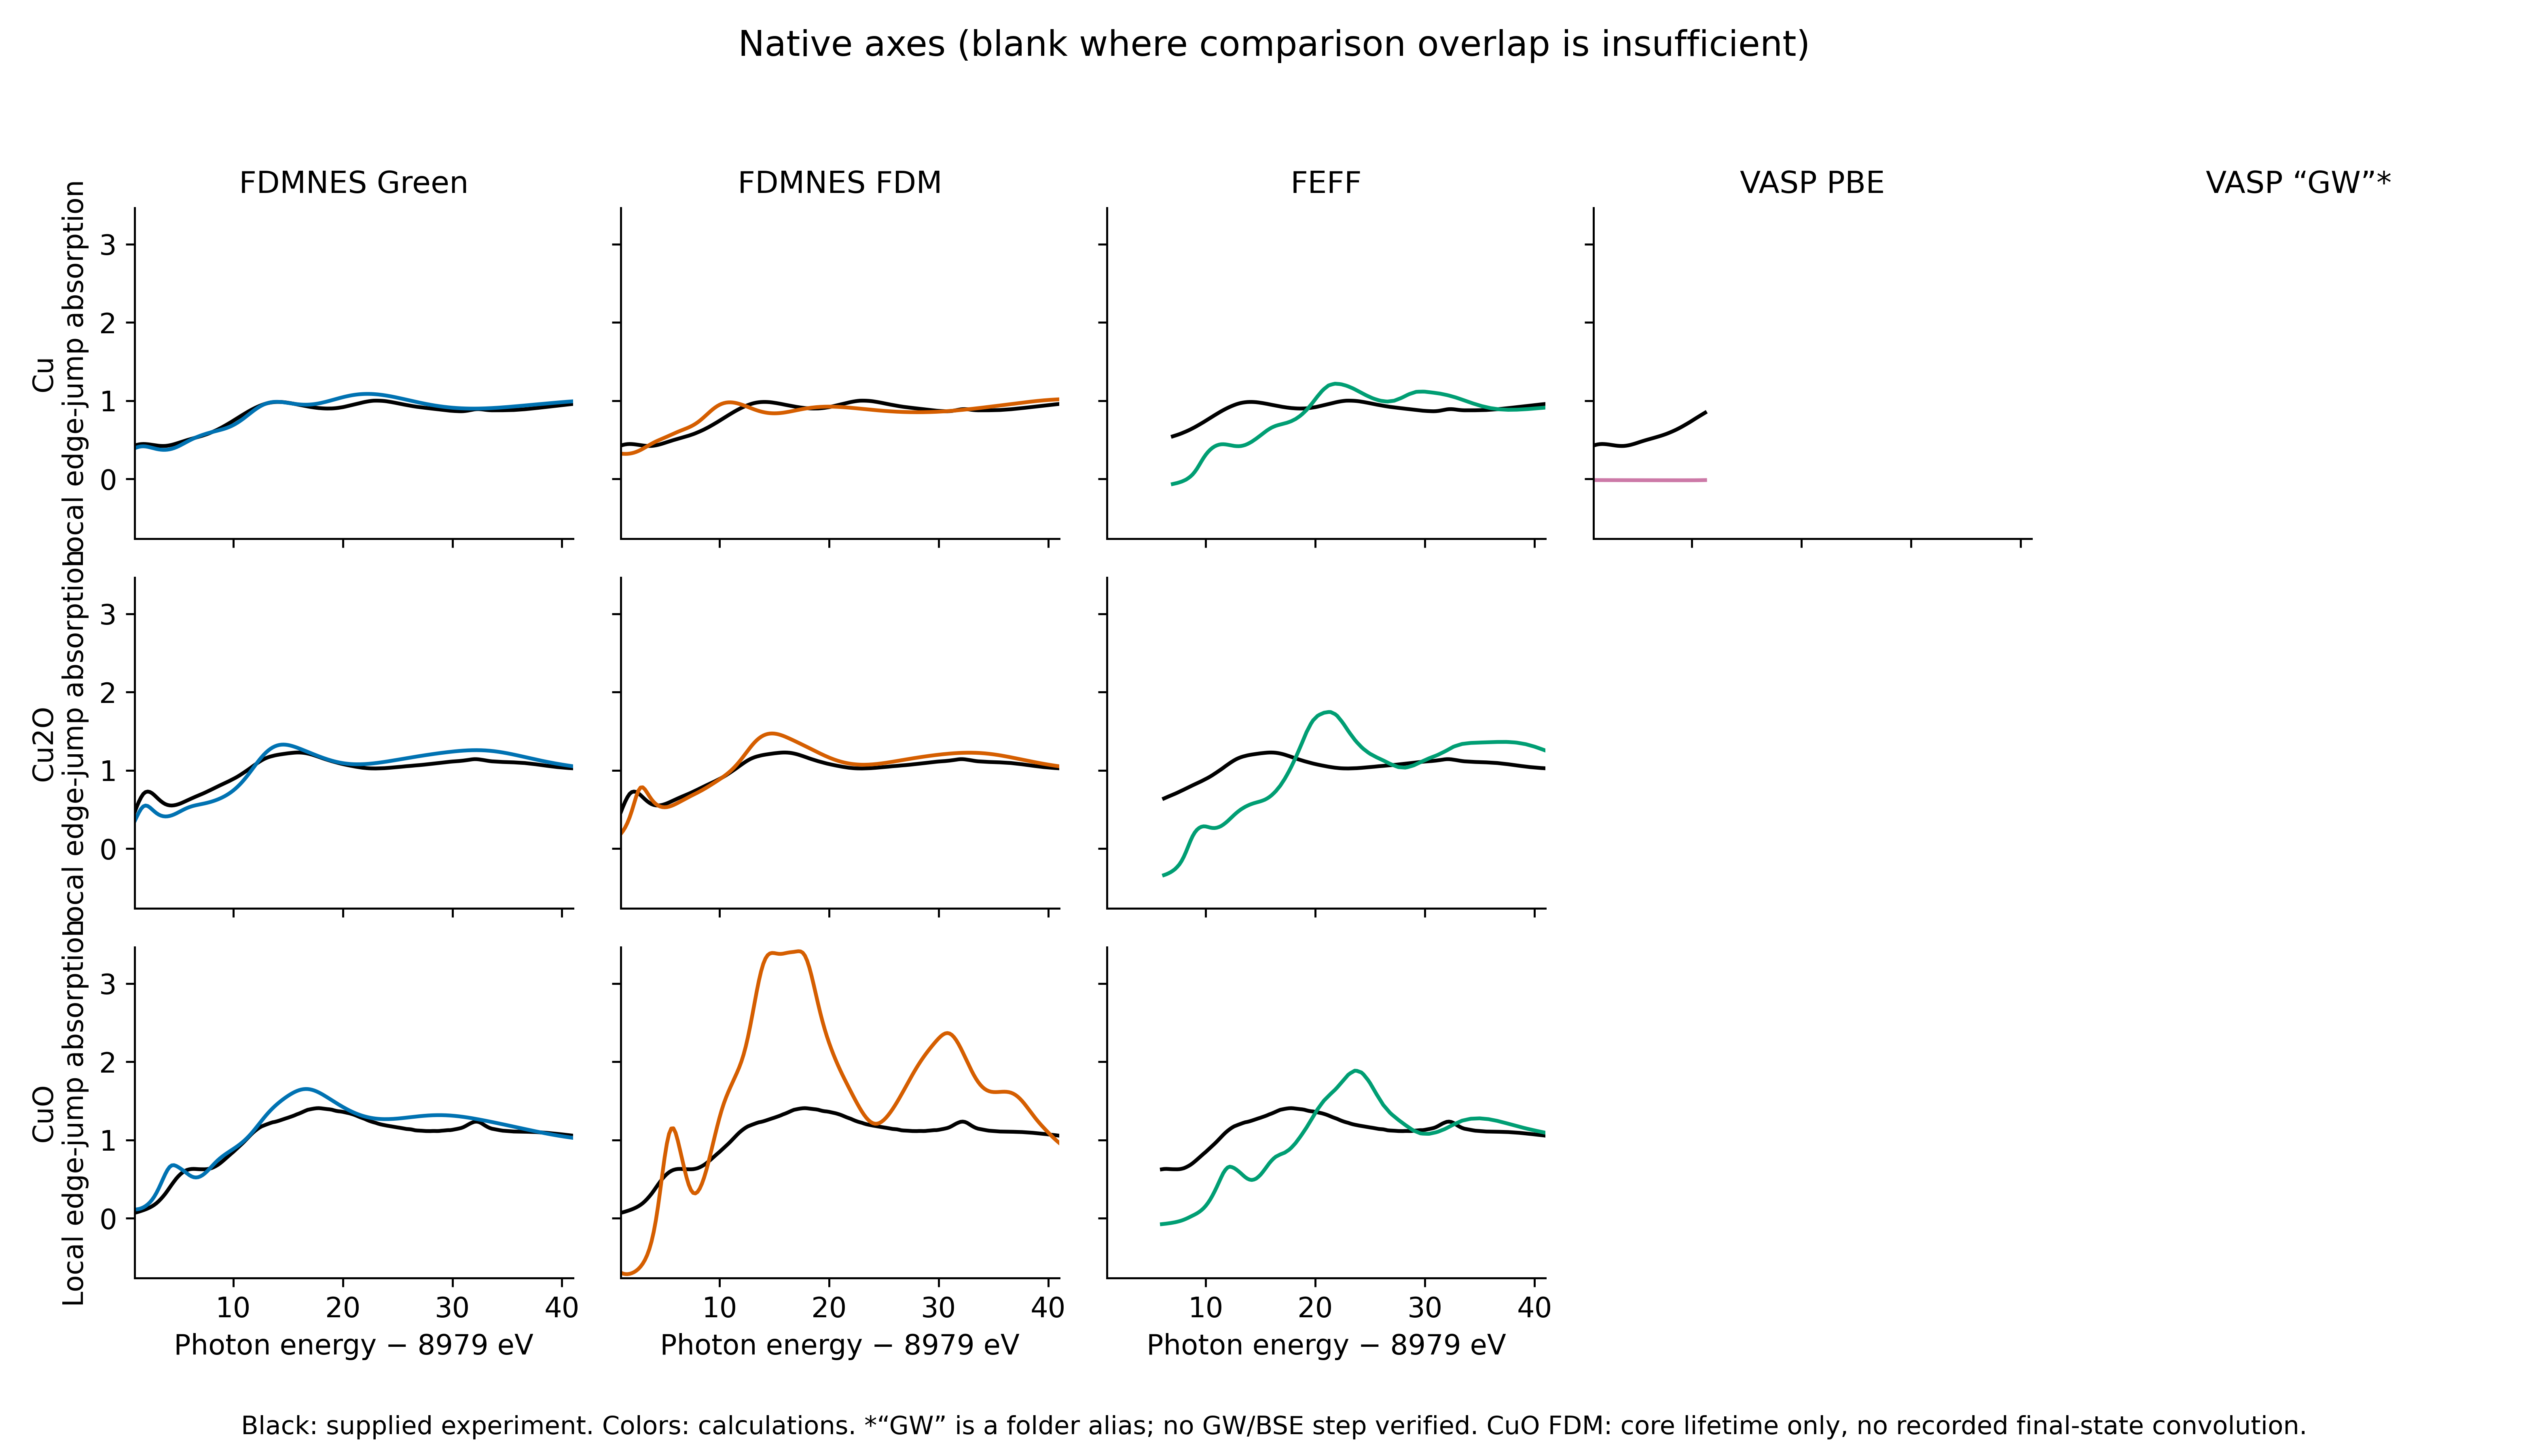

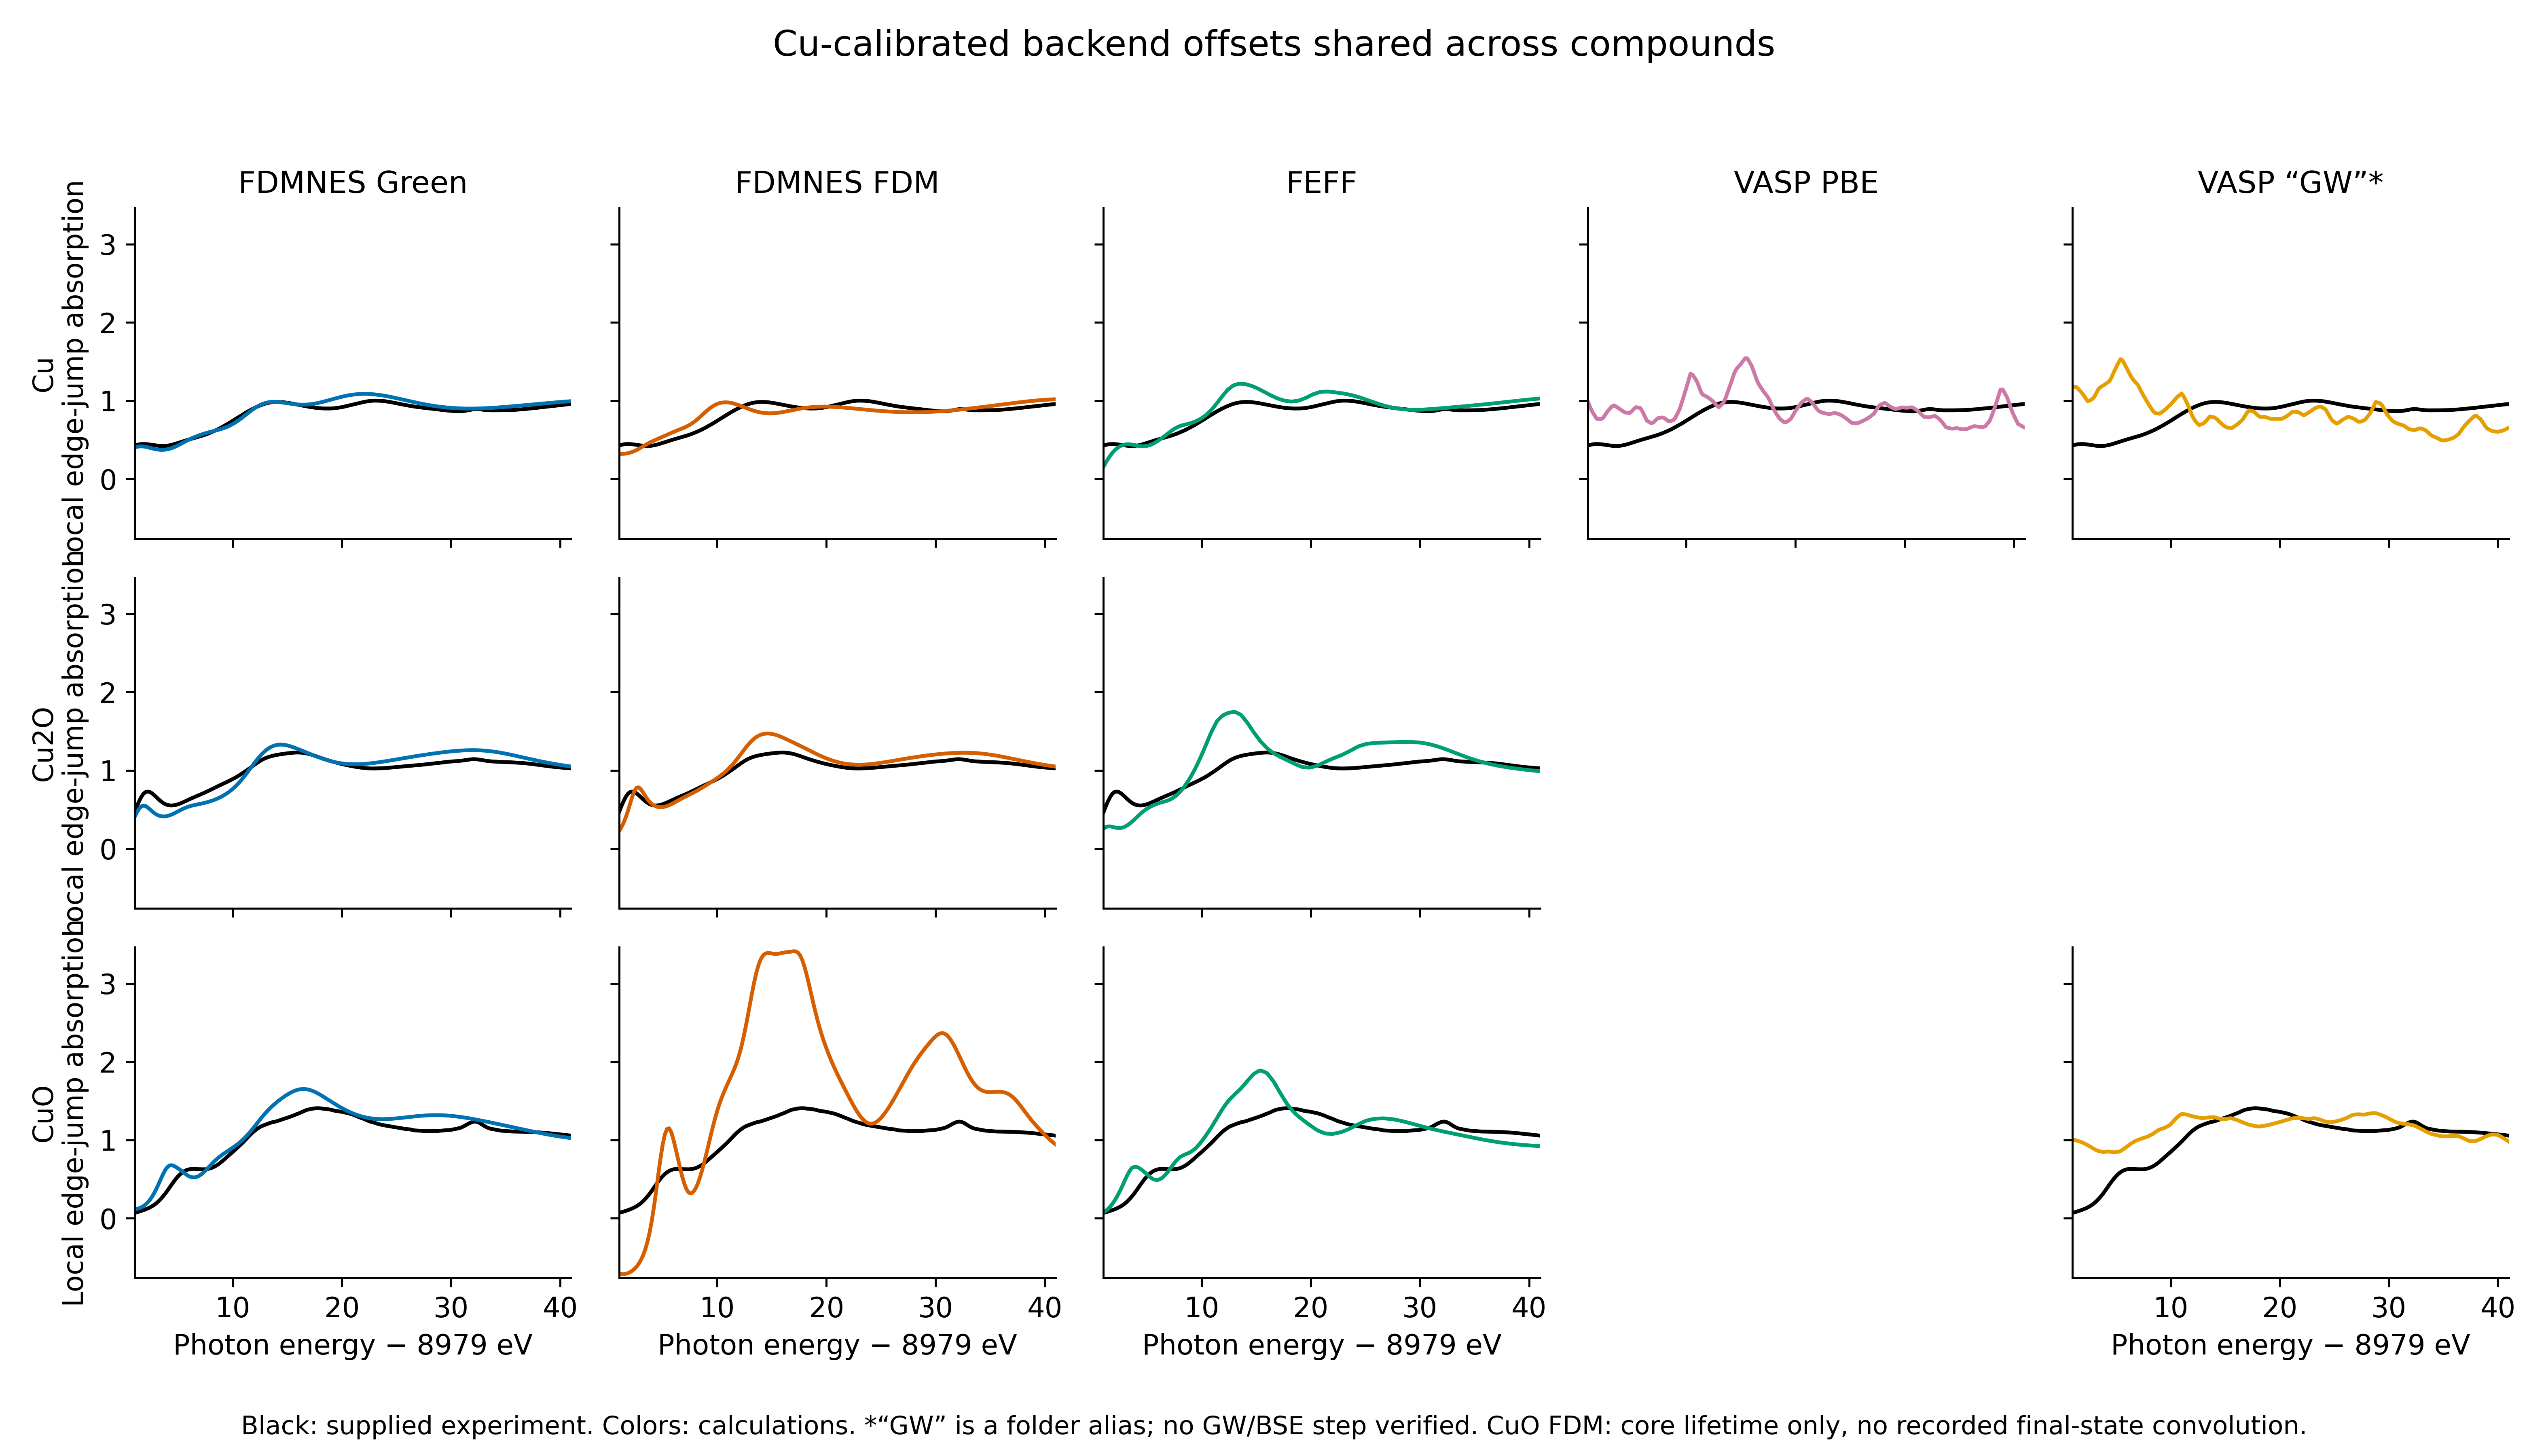

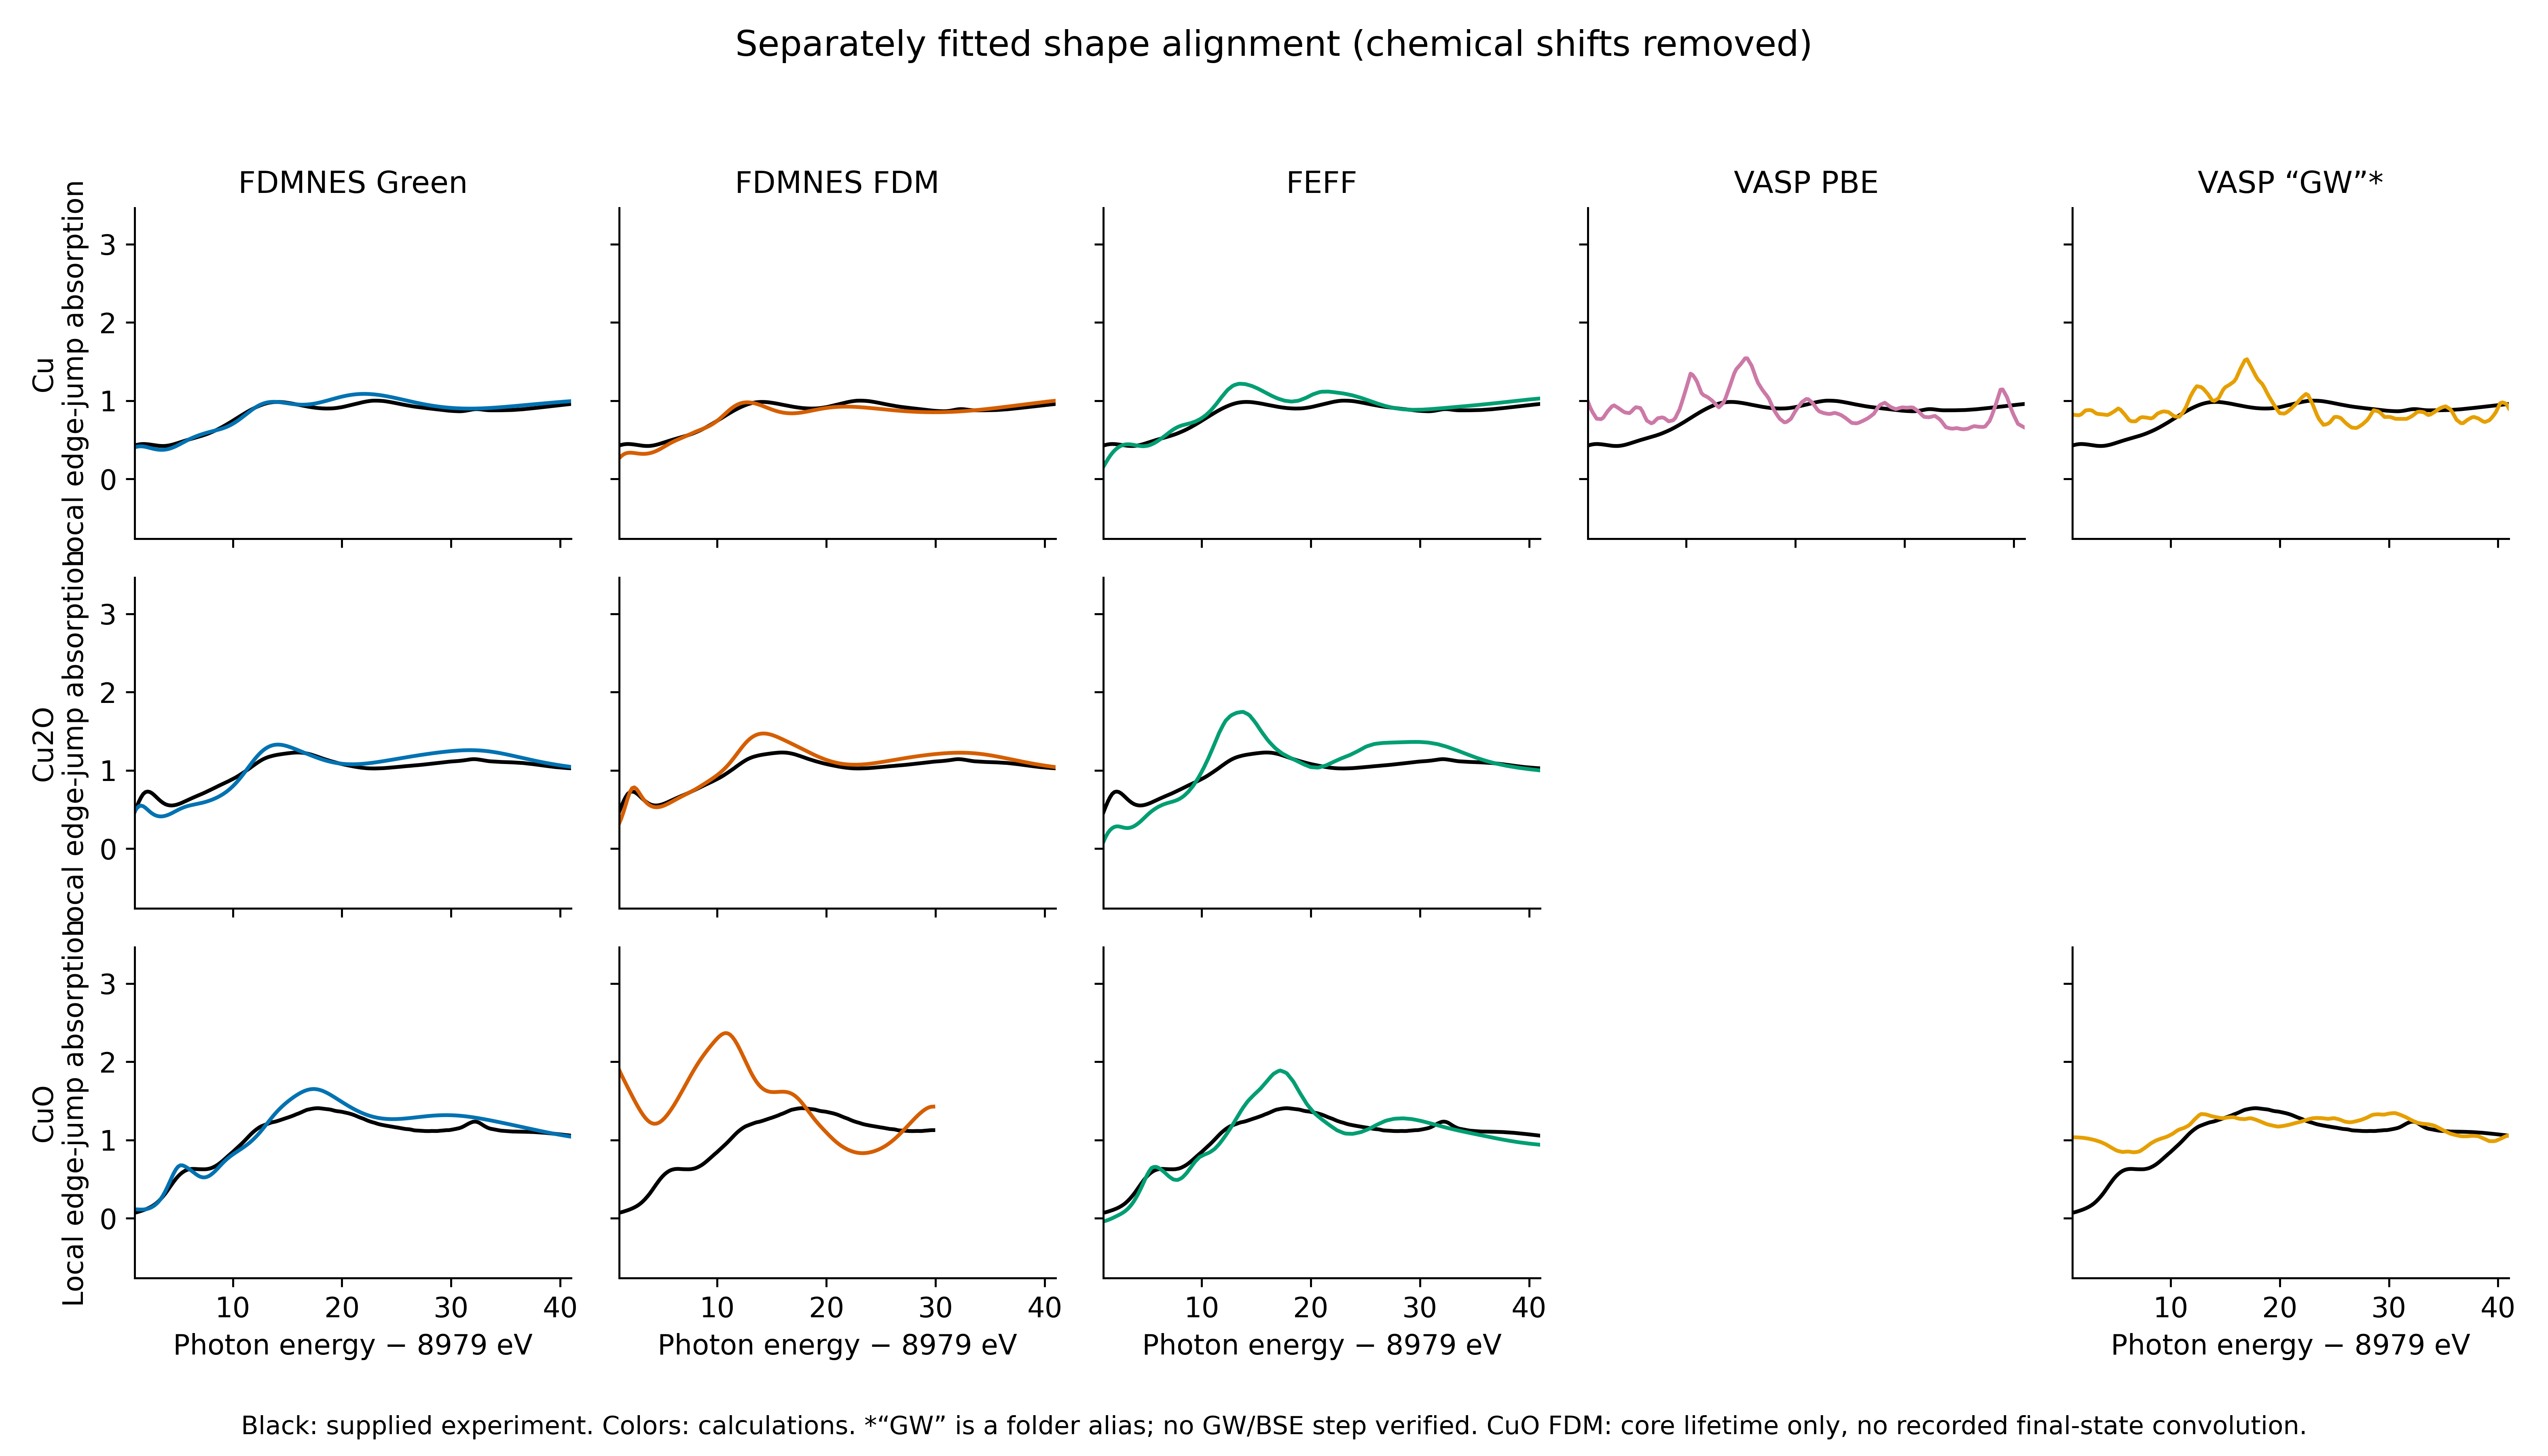

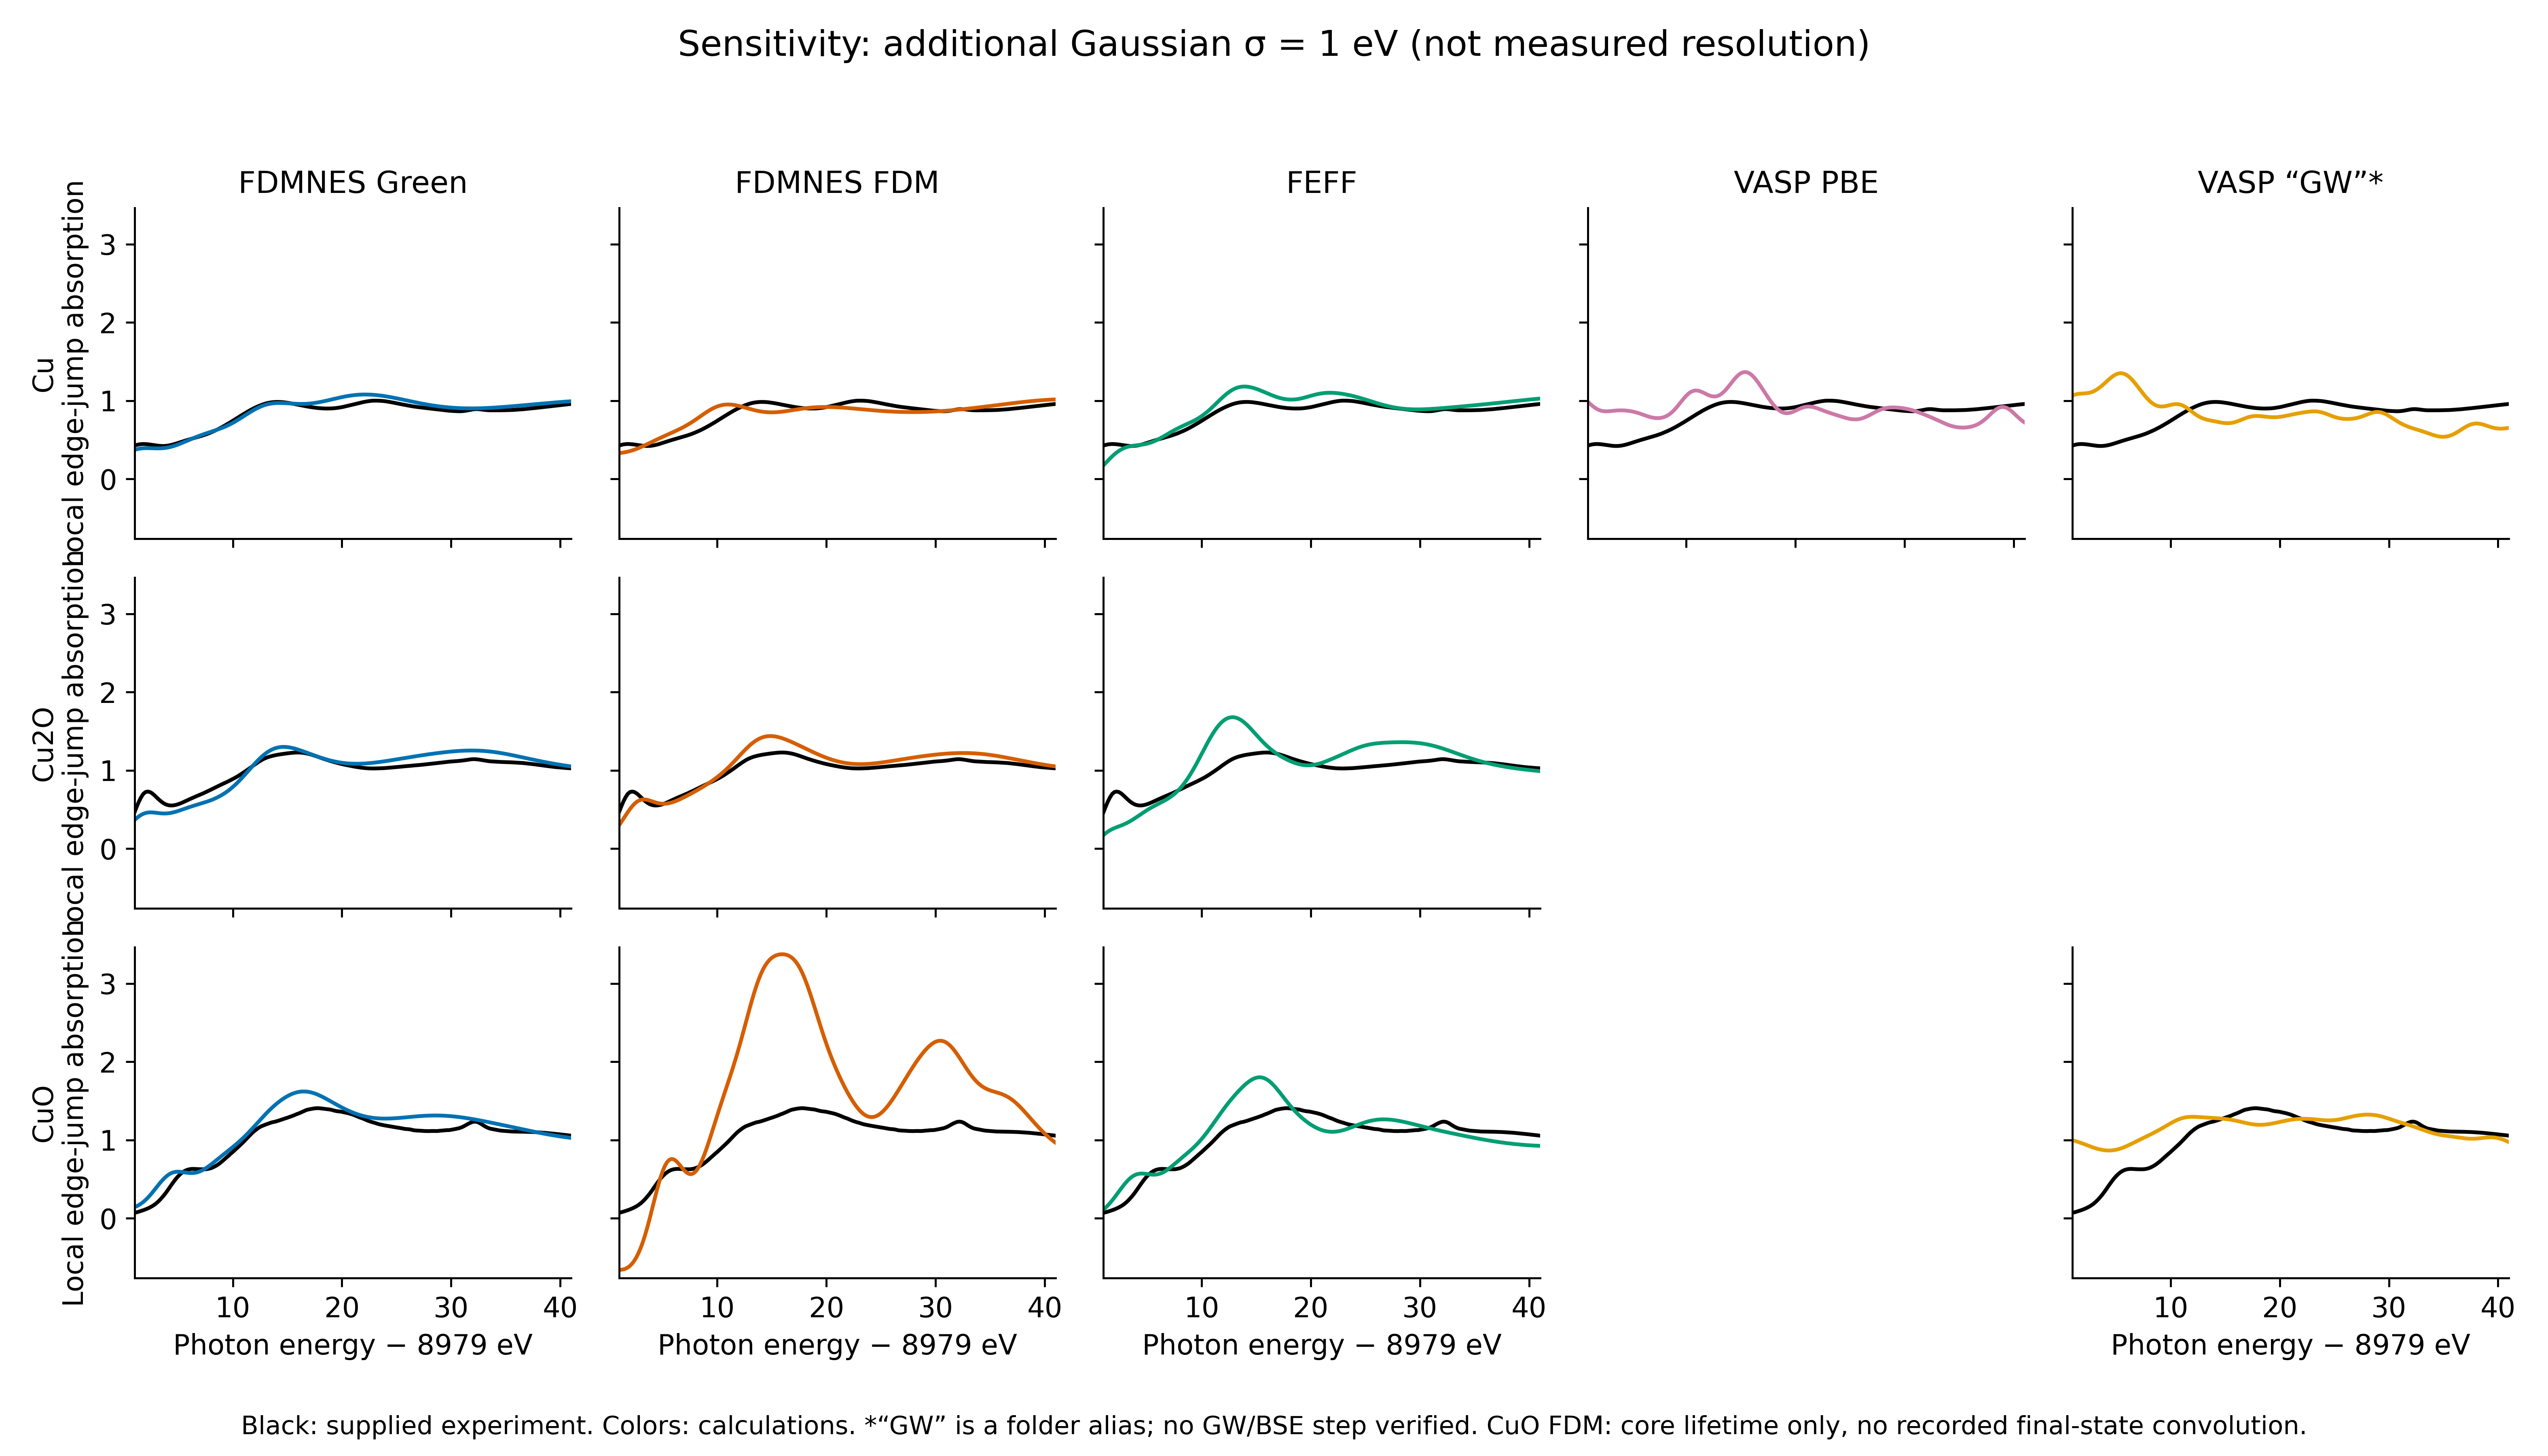

In [4]:
from IPython.display import Image, display
for view in ["native", "common", "shape_aligned", "sigma1_sensitivity"]:
    display(Image(filename=str(root / "figures" / f"reference_grid_{view}.png"), width=1200))